# El EDA de mi proyecto

Es el mismo EDA que el del Titanic, con tus datos: las 9 preguntas, una detrás de otra. Al final se guardan los datos limpios en un CSV, que es el que lee la app.

Debajo de cada bloque hay una celda de texto para escribir lo que has visto y lo que has decidido, en una frase. Si no te acuerdas de cómo se hacía algo, mira titanic.ipynb, eda.ipynb o teoria_eda.ipynb.

## Mis datos

Haz doble clic aquí y escribe de dónde salen tus datos (con el enlace), qué es cada fila y qué pregunta quieres responder.

## 0. Comprobación

In [2]:
import pandas as pd
import matplotlib
import datetime


print("Todo listo")

Todo listo


## 1. ¿Qué tengo?

Empieza por ver qué hay en la tabla.

**1.1** Carga tu CSV de la carpeta datos en una tabla con un nombre que diga qué es (como pisos o titanic) y enseña las primeras filas.

In [3]:
incendios = pd.read_csv("datos/incendios.csv")

incendios.head(5)

,id,superficie,fecha,lat,lng,latlng_explicit,idcomunidad,idprovincia,idmunicipio,municipio,...,causa_supuesta,causa_desc,muertos,heridos,time_ctrl,time_ext,personal,medios,gastos,perdidas
0,1968290001,14.0,1968-01-01,NaN,NaN,NaN,4,29,0,INDETERMINADO,...,1,40,0,0,NaN,360.0,0,0,0.0,0.0
1,1968430003,3.0,1968-01-03,NaN,NaN,NaN,2,43,0,INDETERMINADO,...,1,0,0,0,NaN,60.0,0,0,0.0,0.0
2,1968290006,2.0,1968-01-06,NaN,NaN,NaN,4,29,0,INDETERMINADO,...,1,0,0,0,NaN,120.0,0,0,0.0,0.0
3,1968120007,8.2,1968-01-07,NaN,NaN,NaN,9,12,0,INDETERMINADO,...,1,20,0,0,NaN,120.0,0,0,0.0,0.0
4,1968430016,600.0,1968-01-07,NaN,NaN,NaN,2,43,0,INDETERMINADO,...,1,20,0,0,NaN,1440.0,35,1,0.0,0.0


**1.2** ¿Cuántas filas y columnas tiene?

In [4]:
incendios.shape         # Comprobamos el número de columnas y filas.

(296839, 21)

**1.3** Mira el info(). ¿De qué tipo es cada columna? ¿Cuáles tienen huecos?

In [5]:
incendios.info() # Comprobamos el tipo de datos

<class 'pandas.DataFrame'>
RangeIndex: 296839 entries, 0 to 296838
Data columns (total 21 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               296839 non-null  int64  
 1   superficie       296839 non-null  float64
 2   fecha            296839 non-null  str    
 3   lat              242439 non-null  float64
 4   lng              242439 non-null  float64
 5   latlng_explicit  242446 non-null  float64
 6   idcomunidad      296839 non-null  int64  
 7   idprovincia      296839 non-null  int64  
 8   idmunicipio      296839 non-null  int64  
 9   municipio        296839 non-null  str    
 10  causa            296839 non-null  int64  
 11  causa_supuesta   296839 non-null  int64  
 12  causa_desc       296839 non-null  int64  
 13  muertos          296839 non-null  int64  
 14  heridos          296839 non-null  int64  
 15  time_ctrl        143055 non-null  float64
 16  time_ext         296838 non-null  float64
 17  pe

**1.4** Quédate con las columnas que te sirven para tu pregunta, o quita las que sobran.

In [6]:
incendios = incendios[["superficie", "fecha", "lat", "lng", "latlng_explicit", "idcomunidad", "idprovincia", "municipio", "causa", "causa_supuesta", "muertos", "heridos", "time_ctrl", "time_ext", "personal", "medios", "gastos", "perdidas"]]



# Comenzamos eliminando 3 columnas que no vamos a utilizar, aunque tal vez luego elimine otras.
# El id es solo el numero del incendio, no me aporta información. El id del municipio no lo necesito al ya tener los nombres de los municipios. Y prefiero utilizar la columna de causa que la de causa_desc

**1.5** Si los nombres de las columnas están en inglés o son raros, ponles nombres en español.

In [7]:
incendios.columns = ["hectareas", "fecha", "latitud", "longitud", "ubicación exacta", "comunidad", "provincia", "municipio", "causa", "confirmacion causa", "muertos", "heridos", "tiempo de control", "tiempo de extincion", "personal", "medios", "gastos", "perdidas"]

incendios.head(5)       # Cambiamos el nombre a algunas columnas y comprobamos que esté bien.

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de control,tiempo de extincion,personal,medios,gastos,perdidas
0,14.0,1968-01-01,NaN,NaN,NaN,4,29,INDETERMINADO,2,1,0,0,NaN,360.0,0,0,0.0,0.0
1,3.0,1968-01-03,NaN,NaN,NaN,2,43,INDETERMINADO,5,1,0,0,NaN,60.0,0,0,0.0,0.0
2,2.0,1968-01-06,NaN,NaN,NaN,4,29,INDETERMINADO,5,1,0,0,NaN,120.0,0,0,0.0,0.0
3,8.2,1968-01-07,NaN,NaN,NaN,9,12,INDETERMINADO,3,1,0,0,NaN,120.0,0,0,0.0,0.0
4,600.0,1968-01-07,NaN,NaN,NaN,2,43,INDETERMINADO,3,1,0,0,NaN,1440.0,35,1,0.0,0.0


Lo que he visto y lo que he decidido: Tras analizar las columnas, veo que Id no me aporta nada, Id_municipio, al tener otra con el nombre del municipio tampoco. Y finalmente, causa_desc es demasiado especifica para mi estudio, así que utilizaré causa. Finalmente cambio los nombres para que me sea más fácil trabajar la tabla.

## 2. ¿Qué me falta?

Cuenta lo que falta y decide qué haces con cada columna.

**2.1** Cuenta los huecos de cada columna.

In [8]:
incendios.isna().sum()

hectareas                   0
fecha                       0
latitud                 54400
longitud                54400
ubicación exacta        54393
comunidad                   0
provincia                   0
municipio                   0
causa                       0
confirmacion causa          0
muertos                     0
heridos                     0
tiempo de control      153784
tiempo de extincion         1
personal                    0
medios                      0
gastos                      0
perdidas                    0
dtype: int64

**2.2** Calcula el porcentaje de huecos de cada columna.

In [9]:
round(incendios.isna().sum() / len(incendios) * 100 , 1)

hectareas               0.0
fecha                   0.0
latitud                18.3
longitud               18.3
ubicación exacta       18.3
comunidad               0.0
provincia               0.0
municipio               0.0
causa                   0.0
confirmacion causa      0.0
muertos                 0.0
heridos                 0.0
tiempo de control      51.8
tiempo de extincion     0.0
personal                0.0
medios                  0.0
gastos                  0.0
perdidas                0.0
dtype: float64

**2.3** Decide qué haces con cada columna que tenga huecos: quitar la columna, quitar esas filas o rellenarlos. Hazlo.

In [10]:
incendios = incendios.dropna(subset=["latitud", "longitud", "ubicación exacta"])

incendios.shape

(242439, 18)

In [11]:
print("Tiempo de control de incendios: Mediana", incendios["tiempo de control"].median() , "Media", incendios["tiempo de control"].mean() )



Tiempo de control de incendios: Mediana 140.0 Media 290.574693278339


In [12]:
incendios = incendios.drop(columns = "tiempo de control")  # Esta columna es interesante pero es demasiado incompleta, y para medir el tiempo tenemos la columna de tiempo de extinción



**2.4** Comprueba que ya no quedan huecos, o que los que quedan los dejas a propósito.

In [13]:
incendios = incendios.dropna(subset =["tiempo de extincion"])

In [14]:
incendios.isna().sum()

hectareas              0
fecha                  0
latitud                0
longitud               0
ubicación exacta       0
comunidad              0
provincia              0
municipio              0
causa                  0
confirmacion causa     0
muertos                0
heridos                0
tiempo de extincion    0
personal               0
medios                 0
gastos                 0
perdidas               0
dtype: int64

**2.5** Mira con value_counts las columnas de texto. ¿Hay algún hueco disfrazado, como "Unknown", "-" o "N/A"?

In [15]:
incendios["municipio"].value_counts()

municipio
CANGAS DEL NARCEA          2316
PILOÑA                     2205
TINEO                      1838
VIANA DO BOLO              1726
LLANES                     1679
                           ... 
VILLAGOMEZ LA NUEVA           1
VILLASAYAS                    1
CARRICHES                     1
COZUELOS DE FUENTIDUEÑA       1
ALDEALAFUENTE                 1
Name: count, Length: 7206, dtype: int64

Lo que he visto y lo que he decidido: Tras contar los huecos, veo que hay muchos nulos en latitud, longitud y tiempo de control, así cómo un hueco en tiempo de extinción.

 He quitado todas las filas con latitud y longitud desconocida. Eran demasiadas y no me puedo inventar la ubicación, además que eso podría afectar al mapa después. 

En cuanto al tiempo de control, falta mucha información. La media y la mediana son demasiado diferentes, cambiar los valores desconocidos por la mediana alteraría por completo los datos. Es una información interesante, pero también tenemos el tiempo de extinción.

He eliminado una fila que no tenía tiempo de extinción, al ser sólo una, no se notará su ausencia en el resultado final.

## 3. ¿Hay filas repetidas?

Comprueba si hay algo contado dos veces.

**3.1** ¿Cuántas filas repetidas hay?

In [16]:
print("Filas repetidas", incendios.duplicated().sum())

Filas repetidas 25


**3.2** Si tienes una columna que identifica cada fila (un id, un nombre), ¿hay algún valor repetido?

In [17]:
incendios[incendios.duplicated()].head(25)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
171753,1.60,1998-07-05,41.432321,1.266931,1.0,2,43,BARBERÀ DE LA CONCA,2,1,0,0,143.0,18,5,0.0,0.0
172338,10.00,1998-07-31,40.023320,-5.769695,1.0,14,10,TORREMENGA,4,1,0,0,135.0,43,5,0.0,0.0
177576,1.00,1999-02-07,41.921828,-7.303261,1.0,3,32,VILARDEVÓS,4,0,0,0,45.0,4,1,0.0,0.0
179427,1.00,1999-04-05,39.355808,-5.084769,1.0,14,6,CASTILBLANCO,2,0,0,0,120.0,5,1,0.0,1376.0
179428,1.00,1999-04-05,39.355808,-5.084769,1.0,14,6,CASTILBLANCO,2,0,0,0,120.0,5,1,0.0,1376.0
179534,10.00,1999-04-07,38.482152,-5.673496,1.0,14,6,PERALEDA DEL ZAUCEJO,2,0,0,0,250.0,11,3,0.0,0.0
186444,1.30,2000-03-20,42.218250,-7.369252,1.0,3,32,CHANDREXA DE QUEIXA,4,1,0,0,125.0,5,0,0.0,0.0
189651,1.00,2000-08-29,42.286665,-7.163543,1.0,3,32,MANZANEDA,4,1,0,0,34.0,5,0,0.0,0.0
199193,1.80,2001-12-21,42.052345,-7.907894,1.0,3,32,BANDE,4,1,0,0,210.0,9,1,0.0,0.0
213546,1.00,2003-09-20,42.217695,-7.201441,1.0,3,32,VILARIÑO DE CONSO,4,1,0,0,75.0,11,1,0.0,0.0


**3.3** Decide si las quitas, y hazlo. Si no son la misma fila, no se quitan.

In [18]:
incendios = incendios.drop(index = 179427)   # Así eliminamos el único duplicado real

In [19]:
incendios[incendios.duplicated()].head(25)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
171753,1.60,1998-07-05,41.432321,1.266931,1.0,2,43,BARBERÀ DE LA CONCA,2,1,0,0,143.0,18,5,0.0,0.0
172338,10.00,1998-07-31,40.023320,-5.769695,1.0,14,10,TORREMENGA,4,1,0,0,135.0,43,5,0.0,0.0
177576,1.00,1999-02-07,41.921828,-7.303261,1.0,3,32,VILARDEVÓS,4,0,0,0,45.0,4,1,0.0,0.0
179428,1.00,1999-04-05,39.355808,-5.084769,1.0,14,6,CASTILBLANCO,2,0,0,0,120.0,5,1,0.0,1376.0
179534,10.00,1999-04-07,38.482152,-5.673496,1.0,14,6,PERALEDA DEL ZAUCEJO,2,0,0,0,250.0,11,3,0.0,0.0
186444,1.30,2000-03-20,42.218250,-7.369252,1.0,3,32,CHANDREXA DE QUEIXA,4,1,0,0,125.0,5,0,0.0,0.0
189651,1.00,2000-08-29,42.286665,-7.163543,1.0,3,32,MANZANEDA,4,1,0,0,34.0,5,0,0.0,0.0
199193,1.80,2001-12-21,42.052345,-7.907894,1.0,3,32,BANDE,4,1,0,0,210.0,9,1,0.0,0.0
213546,1.00,2003-09-20,42.217695,-7.201441,1.0,3,32,VILARIÑO DE CONSO,4,1,0,0,75.0,11,1,0.0,0.0
216473,135.00,2004-04-15,42.107452,-6.945089,1.0,17,49,PÍAS,4,0,0,0,1140.0,2,0,0.0,0.0


Lo que he visto y lo que he decidido: Al hacer la lista de duplicados, vemos que hay uno que es realmente un duplicado, así que sacamos sólo ese.

## 4. ¿Cómo son los números?

Mira los números con el describe, la media, la mediana y un histograma.

**4.1** Haz el describe. ¿Qué te llama la atención?

In [20]:
incendios.describe()   
# El incendio más grande es enorme pero he comprobado que es real
# Hay un incendio que pone que tardo casi 6 meses en extinguirse, no puede ser real.
# EL numero maximo de perdidas está por debajo del 75%, no tiene sentido


,hectareas,latitud,longitud,ubicación exacta,comunidad,provincia,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
count,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,242437.000000,2.424370e+05,2.424370e+05
mean,24.292923,41.686413,-5.722239,0.372988,7.505496,27.864818,3.866394,0.772861,0.000751,0.007631,524.183483,22.567030,2.520090,8.175266e+02,1.051647e+04
std,263.708775,1.952367,2.549794,0.483600,5.483804,11.740228,1.028980,0.418984,0.062594,0.182016,1692.451383,45.636149,5.728802,1.644875e+04,2.697969e+05
min,1.000000,27.707179,-18.148781,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,-1352.000000,0.000000,0.000000,0.000000e+00,0.000000e+00
25%,1.500000,40.853846,-7.520661,0.000000,3.000000,19.000000,4.000000,1.000000,0.000000,0.000000,135.000000,6.000000,0.000000,0.000000e+00,0.000000e+00
50%,3.000000,42.340465,-6.285200,0.000000,5.000000,32.000000,4.000000,1.000000,0.000000,0.000000,240.000000,12.000000,1.000000,0.000000e+00,0.000000e+00
75%,9.000000,43.060419,-4.382002,1.000000,13.000000,36.000000,4.000000,1.000000,0.000000,0.000000,448.000000,25.000000,3.000000,0.000000e+00,6.010000e+02
max,29867.000000,43.765502,4.274832,1.000000,18.000000,51.000000,6.000000,1.000000,20.000000,30.000000,230370.000000,3612.000000,438.000000,2.793745e+06,5.484489e+07


**4.2** Saca la media y la mediana de la columna de números más importante para tu pregunta. ¿Se parecen?

In [21]:
print("Hectáreas quemadas: Mediana", int(incendios["hectareas"].median()) , "Media", int(incendios["hectareas"].mean()) )

Hectáreas quemadas: Mediana 3 Media 24


**4.3** Dibuja su histograma.

<Axes: title={'center': 'Hectáreas quemadas'}, ylabel='Frequency'>

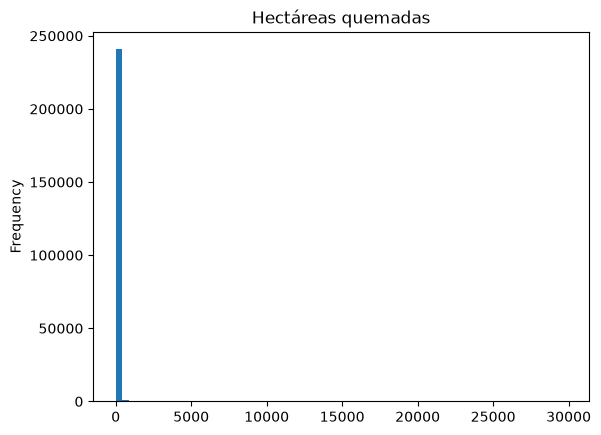

In [22]:
incendios["hectareas"].plot(kind= "hist", bins = 70, title = "Hectáreas quemadas")  

**4.4** Haz lo mismo con otra columna de números.

<Axes: title={'center': 'Personal presente'}, ylabel='Frequency'>

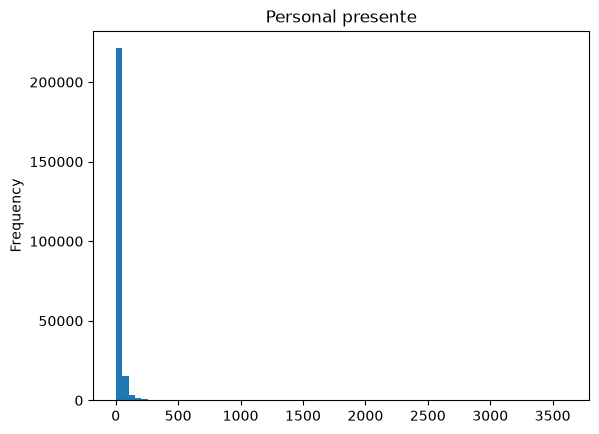

In [23]:
incendios["personal"].plot(kind= "hist", bins = 70, title = "Personal presente")  

Lo que he visto y lo que he decidido: Hay muchos incendios muy pequeños sin casi consecuencias, me planteo quitarlos para trabajar con el resto de datos.

## 5. ¿Hay algo raro?

Busca los valores extremos y decide si son errores o casos reales.

**5.1** Enseña las 5 filas con el valor más alto de tu columna principal.

In [24]:
incendios.sort_values("hectareas", ascending = False).head(5)   # He comprobado que el mayor incendio es real.

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
218907,29867.0,2004-07-27,37.691760,-6.599990,1.0,4,21,MINAS DE RIOTINTO,4,0,0,1,11065.0,1504,123,0.0,4488390.0
263245,28879.1,2012-06-28,39.269115,-0.955787,1.0,9,46,CORTES DE PALLÁS,3,0,1,0,24772.0,540,146,0.0,12607966.0
139510,28213.3,1994-07-02,40.637450,-0.527527,0.0,10,44,VILLARLUENGO,1,1,0,0,8790.0,1063,64,95861.0,23637217.0
139555,25579.0,1994-07-04,38.568266,-1.727008,0.0,11,2,HELLÍN,2,1,0,0,7200.0,936,137,974753.0,2317275.0
139623,25430.0,1994-07-04,39.224837,-0.845232,0.0,9,46,MILLARES,1,1,9,0,11910.0,423,34,0.0,6350780.0


**5.2** Y las 5 con el más bajo. ¿Hay ceros o valores imposibles?

In [25]:
incendios.sort_values("hectareas", ascending = True).head(5) 

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
296809,1.0,2022-12-31,43.330568,-5.652539,1.0,5,33,LANGREO,4,1,0,0,172.0,3,2,0.0,0.0
296786,1.0,2022-12-21,43.320291,-5.425302,1.0,5,33,PILOÑA,4,1,0,0,4501.0,3,2,0.0,0.0
54453,1.0,1983-01-22,42.329642,-7.332653,0.0,3,32,"POBRA DE TRIVES, A",4,1,0,0,900.0,5,0,0.0,0.0
296757,1.0,2022-11-07,43.445497,-5.049705,1.0,5,33,RIBADESELLA,4,1,0,0,1038.0,3,2,0.0,0.0
214298,1.0,2004-02-06,43.050841,-6.702613,0.0,5,33,CANGAS DEL NARCEA,2,1,0,0,90.0,2,0,0.0,0.0


**5.3** Haz el diagrama de caja de esa columna.

<Axes: title={'center': 'Hectareas quemadas'}>

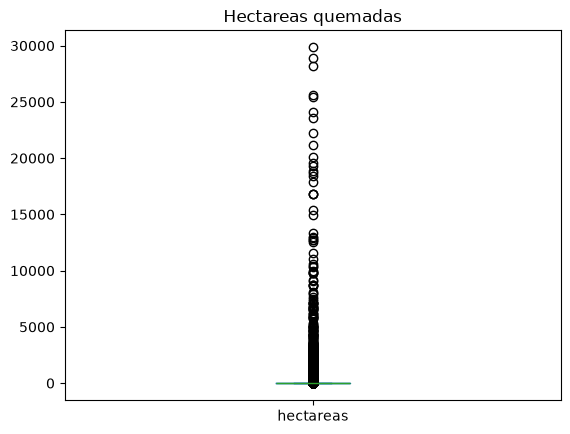

In [26]:
incendios["hectareas"].plot(kind= "box", title = "Hectareas quemadas")

**5.4** Decide qué haces con cada valor raro: si es un error, corrígelo o quítalo; si es real, se queda.

In [27]:
incendios.sort_values("perdidas", ascending = False).head(5)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
139576,13323.30,1994-07-04,41.816114,1.663651,0.0,2,8,SANT MATEU DE BAGES,5,1,0,15,10481.0,1555,89,0.0,54844893.0
282371,3485.46,2017-10-14,41.876109,-8.014878,1.0,3,32,LOBIOS,5,0,0,0,6850.0,225,12,0.0,45177750.0
263255,20064.90,2012-06-29,39.759251,-0.776686,1.0,9,46,ANDILLA,3,0,0,2,30474.0,3498,433,0.0,41040142.0
139574,16832.80,1994-07-04,42.107886,1.680761,0.0,2,8,MONTMAJOR,3,1,2,30,23503.0,3612,265,0.0,32713336.0
295740,12768.22,2022-07-14,42.598991,-7.322375,1.0,3,27,"POBLA DO BROLLÓN, A",1,0,0,2,19648.0,788,117,2702306.0,32063433.0


In [28]:
incendios.sort_values("tiempo de extincion", ascending = False).head(5)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
292886,3052.00,2021-05-20,28.229735,-16.491632,1.0,12,38,ARICO,4,0,0,0,230370.0,366,168,0.0,0.0
293862,6.38,2021-08-28,41.159453,1.238266,1.0,2,43,CONSTANTÍ,2,0,0,0,176119.0,104,14,0.0,0.0
293092,1.50,2021-06-22,37.251370,-3.733061,1.0,4,18,PINOS PUENTE,5,0,0,0,175834.0,16,1,347.0,0.0
263405,6512.00,2012-07-15,28.139638,-16.690348,1.0,12,38,ADEJE,2,0,0,1,152365.0,504,52,0.0,0.0
255892,2.00,2011-05-25,39.039264,-5.836481,1.0,14,6,DON BENITO,4,1,0,0,135120.0,12,3,0.0,0.0


Lo que he visto y lo que he decidido:

In [29]:
round(len(incendios[incendios["gastos"] == 0]) / len(incendios) * 100, 1)   # Gastos era una columna muy interesante, pero me faltan el 81% de datos

81.0

In [30]:
round(len(incendios[incendios["perdidas"] == 0]) / len(incendios) * 100, 1)

57.0

In [31]:
incendios2 = incendios[incendios["gastos"] > 1000]
incendios2 = incendios2[incendios2["perdidas"] > 1000]

incendios2.head(5)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios,gastos,perdidas
85720,5.5,1988-02-15,43.118846,-2.284244,0.0,1,20,AZPEITIA,2,1,0,0,360.0,20,0,1851.0,9982.0
85974,20.0,1988-03-11,40.567655,-2.326597,0.0,11,16,ALCANTUD,2,1,0,0,420.0,50,0,3005.0,19894.0
85990,50.0,1988-03-11,42.658411,-8.556970,0.0,3,36,CUNTIS,2,1,0,0,420.0,17,1,1503.0,53322.0
86045,37.0,1988-03-13,42.089530,-8.736783,0.0,3,36,GONDOMAR,4,1,0,0,1200.0,11,1,1112.0,30123.0
86071,230.0,1988-03-14,43.418427,-5.857440,0.0,5,33,LLANERA,5,1,0,0,3360.0,23,2,2644.0,185238.0


In [32]:
incendios = incendios.drop(columns = ["gastos", "perdidas"])  #Tras mucho analizar, las columnas de gastos y perdidas están muy incompletas, así que las descarto.

incendios.head(5)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios
39711,20.0,1980-09-18,42.376191,-7.004868,0.0,3,32,"BARCO DE VALDEORRAS, O",4,1,0,0,420.0,12,0
54383,2.0,1983-01-04,38.942962,-0.361213,0.0,9,46,LUTXENT,5,1,0,0,180.0,13,0
54384,15.0,1983-01-05,40.133460,-0.686263,0.0,10,44,RUBIELOS DE MORA,2,1,0,0,360.0,78,0
54385,15.0,1983-01-05,39.302764,-0.777780,0.0,9,46,DOS AGUAS,5,1,0,0,300.0,63,1
54386,95.0,1983-01-06,40.242209,-0.056820,0.0,9,12,SIERRA ENGARCERÁN,4,1,0,0,1440.0,22,0


### He decidido eliminar las columnas de gastos y pérdidas, pues estaban también demasiado incompletas.
### Me sorprendían los máximos de hectáreas y de tiempo de extinción, pero he comprobado que son ciertos
### En el caso de tiempo de extinción, un incendio puede tardar semanas o incluso meses para considerar que se ha extinguido

## 6. ¿Qué hay más?

Cuántas filas hay de cada tipo.

**6.1** Haz el value_counts de la columna de texto más importante, en número y en porcentaje.

In [33]:
incendios["provincia"] = incendios["provincia"].replace({
    1: "Álava",
    2: "Albacete",
    3: "Alicante",
    4: "Almería",
    5: "Ávila",
    6: "Badajoz",
    7: "Islas Baleares",
    8: "Barcelona",
    9: "Burgos",
    10: "Cáceres",
    11: "Cádiz",
    12: "Castellón",
    13: "Ciudad Real",
    14: "Córdoba",
    15: "A Coruña",
    16: "Cuenca",
    17: "Girona",
    18: "Granada",
    19: "Guadalajara",
    20: "Gipuzkoa",
    21: "Huelva",
    22: "Huesca",
    23: "Jaén",
    24: "León",
    25: "Lleida",
    26: "La Rioja",
    27: "Lugo",
    28: "Madrid",
    29: "Málaga",
    30: "Murcia",
    31: "Navarra",
    32: "Ourense",
    33: "Asturias",
    34: "Palencia",
    35: "Las Palmas",
    36: "Pontevedra",
    37: "Salamanca",
    38: "Santa Cruz de Tenerife",
    39: "Cantabria",
    40: "Segovia",
    41: "Sevilla",
    42: "Soria",
    43: "Tarragona",
    44: "Teruel",
    45: "Toledo",
    46: "Valencia",
    47: "Valladolid",
    48: "Bizkaia",
    49: "Zamora",
    50: "Zaragoza",
    51: "Ceuta",
    52: "Melilla"
})


incendios.tail(5)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios
296834,2.15,2023-10-16,38.325658,-1.278815,1.0,8,Murcia,JUMILLA,2,0,0,0,325.0,42,6
296835,4.70,2023-10-19,37.629960,-0.841844,1.0,8,Murcia,CARTAGENA,3,0,0,0,732.0,35,7
296836,1.18,2023-11-27,38.485454,-1.343063,1.0,8,Murcia,JUMILLA,2,1,0,0,301.0,24,4
296837,1.03,2023-12-02,37.968893,-1.548739,1.0,8,Murcia,MULA,4,0,0,0,210.0,9,1
296838,1.80,2023-12-08,37.608123,-1.012078,1.0,8,Murcia,CARTAGENA,4,0,0,0,138.0,10,2


In [34]:
incendios["comunidad"] = incendios["comunidad"].replace({
    1: "País Vasco",
    2: "Cataluña",
    3: "Galicia",
    4: "Andalucía",
    5: "Asturias",
    6: "Cantabria",
    7: "La Rioja",
    8: "Murcia",
    9: "Comunidad Valenciana",
    10: "Aragón",
    11: "Castilla-La Mancha",
    12: "Islas Canarias",
    13: "Navarra",
    14: "Extremadura",
    15: "Islas Baleares",
    16: "Madrid",
    17: "Castilla y León",
    18: "Ceuta y Melilla"
    
})

incendios.head(5)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios
39711,20.0,1980-09-18,42.376191,-7.004868,0.0,Galicia,Ourense,"BARCO DE VALDEORRAS, O",4,1,0,0,420.0,12,0
54383,2.0,1983-01-04,38.942962,-0.361213,0.0,Comunidad Valenciana,Valencia,LUTXENT,5,1,0,0,180.0,13,0
54384,15.0,1983-01-05,40.133460,-0.686263,0.0,Aragón,Teruel,RUBIELOS DE MORA,2,1,0,0,360.0,78,0
54385,15.0,1983-01-05,39.302764,-0.777780,0.0,Comunidad Valenciana,Valencia,DOS AGUAS,5,1,0,0,300.0,63,1
54386,95.0,1983-01-06,40.242209,-0.056820,0.0,Comunidad Valenciana,Castellón,SIERRA ENGARCERÁN,4,1,0,0,1440.0,22,0


In [35]:
incendios["comunidad"].value_counts()

comunidad
Galicia                 82578
Castilla y León         39754
Asturias                30853
Andalucía               17982
Extremadura             16735
Cantabria               14969
Castilla-La Mancha       9498
Cataluña                 6379
Comunidad Valenciana     5956
Aragón                   4016
Navarra                  3482
País Vasco               3425
Madrid                   2871
La Rioja                 1317
Islas Baleares            937
Murcia                    867
Islas Canarias            800
Ceuta y Melilla            18
Name: count, dtype: int64

In [36]:
incendios["causa"] = incendios["causa"].replace({
    1: "Causa Natural",
    2: "Negligencias y accidentes",
    3: "Intencionados",
    4: "Causa desconocida",
    5: "Reproducciones",
    6: "Otras causas humanas"
})

In [37]:
round(incendios["causa"].value_counts() / len(incendios) * 100, 1)

causa
Causa desconocida            55.2
Reproducciones               23.9
Negligencias y accidentes    14.3
Intencionados                 3.6
Causa Natural                 2.2
Otras causas humanas          0.8
Name: count, dtype: float64

### Las columnas de comunidad, provincia y causa no indicaban los nombres sino códigos numéricos. Los he cambiado por los nombres correspondientes.

In [38]:
incendios["ubicación exacta"] = incendios["ubicación exacta"].replace({
    1: "Si",
    0: "Municipio más cercano"
})


In [39]:
incendios["confirmacion causa"] = incendios["confirmacion causa"].replace({
    1: "Supuesta",
    0: "Confirmada"
})

In [40]:
incendios["confirmacion causa"].value_counts()

confirmacion causa
Supuesta      187370
Confirmada     55067
Name: count, dtype: int64

**6.2** Dibújalo en barras.

<Axes: ylabel='comunidad'>

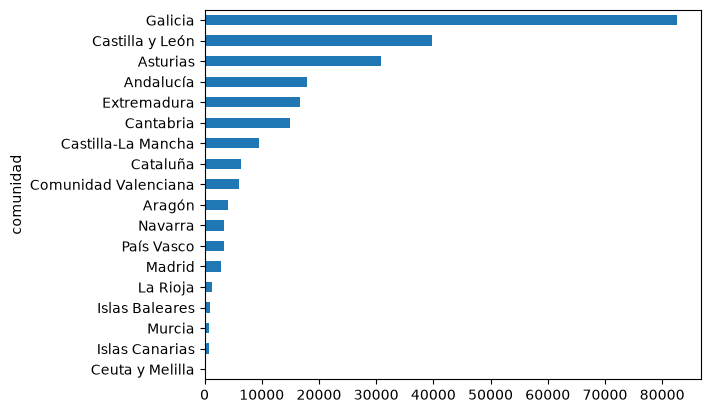

In [41]:
incendios["comunidad"].value_counts(ascending = True).plot(kind = "barh")

Lo que he visto y lo que he decidido: He cambiado los nombres de las columnas comunidad, provincia, causa, confirmación causa, y ubicación exacta. Lo he hecho para que muestren nombres que den la información más fácilmente que hacerlo con varios códigos numéricos distintos.

## 7. ¿Cambia algo de un grupo a otro?

Aquí es donde suelen salir los hallazgos.

**7.1** Con groupby, calcula la media o la mediana de tu columna principal en cada grupo.

In [42]:
incendios.groupby("comunidad")["hectareas"].mean().round(1)

comunidad
Andalucía                34.2
Aragón                   45.4
Asturias                 13.9
Cantabria                15.6
Castilla y León          30.2
Castilla-La Mancha       32.9
Cataluña                 49.1
Ceuta y Melilla          24.1
Comunidad Valenciana     86.2
Extremadura              29.7
Galicia                  15.7
Islas Baleares           29.2
Islas Canarias          143.1
La Rioja                 12.3
Madrid                   16.2
Murcia                   13.3
Navarra                  10.6
País Vasco               10.9
Name: hectareas, dtype: float64

**7.2** Haz otra comparación con otra columna de grupos.

In [43]:
incendios.groupby("comunidad")["personal"].mean().round(1)

comunidad
Andalucía               42.5
Aragón                  38.5
Asturias                 7.4
Cantabria                8.6
Castilla y León         23.5
Castilla-La Mancha      34.1
Cataluña                47.2
Ceuta y Melilla         60.9
Comunidad Valenciana    56.6
Extremadura             24.8
Galicia                 18.3
Islas Baleares          52.9
Islas Canarias          71.0
La Rioja                19.2
Madrid                  38.9
Murcia                  44.6
Navarra                 10.5
País Vasco              16.9
Name: personal, dtype: float64

In [44]:
incendios[incendios["muertos"] > 0].groupby("comunidad")["muertos"].mean()

comunidad
Andalucía               2.444444
Aragón                  2.333333
Asturias                1.000000
Castilla y León         1.428571
Castilla-La Mancha      2.100000
Cataluña                1.750000
Comunidad Valenciana    1.875000
Extremadura             1.333333
Galicia                 1.250000
Islas Canarias          5.750000
Madrid                  3.000000
Navarra                 1.000000
País Vasco              1.000000
Name: muertos, dtype: float64

**7.3** Antes de sacar conclusiones, mira cuántas filas tiene cada grupo. ¿Hay alguno con muy pocas?

In [45]:
incendios.tail(1)

,hectareas,fecha,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios
296838,1.8,2023-12-08,37.608123,-1.012078,Si,Murcia,Murcia,CARTAGENA,Causa desconocida,Confirmada,0,0,138.0,10,2


Lo que he visto y lo que he decidido:

## 8. ¿Van juntas dos columnas?

Comprueba si dos columnas de números tienen relación.

**8.1** Calcula la correlación entre dos columnas de números.

In [46]:
print(incendios["tiempo de extincion"].corr(incendios["personal"]).round(1))

0.4


**8.2** Haz el gráfico de puntos de esas dos columnas.

<Axes: xlabel='hectareas', ylabel='muertos'>

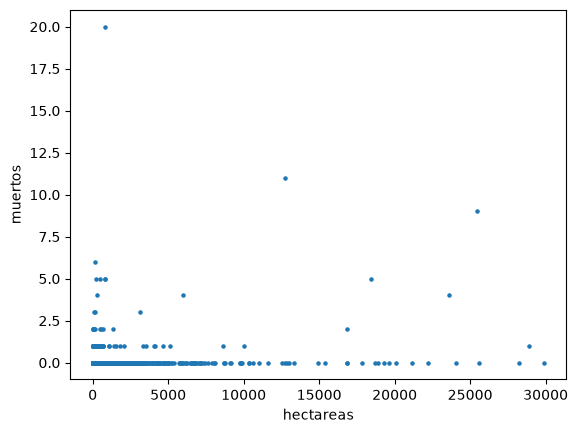

In [47]:
incendios.plot(kind = "scatter", x = "hectareas", y = "muertos", s = 5)

Lo que he visto y lo que he decidido:

## 9. ¿Qué he aprendido?

**9.1** Haz doble clic en la celda de abajo y escribe tus tres hallazgos, cada uno en una frase con un número. Añade otra con lo que has quitado o cambiado en los datos. Esto es lo que irá en el README y en la presentación.

Escribe aquí tus hallazgos.

## 10. Guardar los datos limpios

**10.1** Guarda la tabla limpia en datos/datos_limpios.csv con to_csv y index=False. Es el archivo que lee la app.

Resultado esperado: un archivo nuevo, datos_limpios.csv, en la carpeta datos.

In [48]:
incendios2["provincia"] = incendios2["provincia"].replace({
    1: "Álava",
    2: "Albacete",
    3: "Alicante",
    4: "Almería",
    5: "Ávila",
    6: "Badajoz",
    7: "Islas Baleares",
    8: "Barcelona",
    9: "Burgos",
    10: "Cáceres",
    11: "Cádiz",
    12: "Castellón",
    13: "Ciudad Real",
    14: "Córdoba",
    15: "A Coruña",
    16: "Cuenca",
    17: "Girona",
    18: "Granada",
    19: "Guadalajara",
    20: "Gipuzkoa",
    21: "Huelva",
    22: "Huesca",
    23: "Jaén",
    24: "León",
    25: "Lleida",
    26: "La Rioja",
    27: "Lugo",
    28: "Madrid",
    29: "Málaga",
    30: "Murcia",
    31: "Navarra",
    32: "Ourense",
    33: "Asturias",
    34: "Palencia",
    35: "Las Palmas",
    36: "Pontevedra",
    37: "Salamanca",
    38: "Santa Cruz de Tenerife",
    39: "Cantabria",
    40: "Segovia",
    41: "Sevilla",
    42: "Soria",
    43: "Tarragona",
    44: "Teruel",
    45: "Toledo",
    46: "Valencia",
    47: "Valladolid",
    48: "Bizkaia",
    49: "Zamora",
    50: "Zaragoza",
    51: "Ceuta",
    52: "Melilla"
})

In [49]:
incendios2["causa"] = incendios2["causa"].replace({
    1: "Causa Natural",
    2: "Negligencias y accidentes",
    3: "Intencionados",
    4: "Causa desconocida",
    5: "Reproducciones",
    6: "Otras causas humanas"
})

In [50]:
incendios2["comunidad"] = incendios2["comunidad"].replace({
    1: "País Vasco",
    2: "Cataluña",
    3: "Galicia",
    4: "Andalucía",
    5: "Asturias",
    6: "Cantabria",
    7: "La Rioja",
    8: "Murcia",
    9: "Comunidad Valenciana",
    10: "Aragón",
    11: "Castilla-La Mancha",
    12: "Islas Canarias",
    13: "Navarra",
    14: "Extremadura",
    15: "Islas Baleares",
    16: "Madrid",
    17: "Castilla y León",
    18: "Ceuta y Melilla"
    
})


In [51]:
incendios2["muertos"].corr(incendios2["perdidas"])

np.float64(0.2741694392765328)

In [52]:
incendios2["ubicación exacta"].value_counts()

ubicación exacta
0.0    4140
1.0    4098
Name: count, dtype: int64

In [53]:
incendios.insert(
    2,
    "año",
    pd.to_datetime(incendios["fecha"], dayfirst=True).dt.year
)

incendios.head(4)

C:\Users\Propietario\AppData\Local\Temp\ipykernel_16912\4252537815.py:4: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  pd.to_datetime(incendios["fecha"], dayfirst=True).dt.year


,hectareas,fecha,año,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios
39711,20.0,1980-09-18,1980,42.376191,-7.004868,Municipio más cercano,Galicia,Ourense,"BARCO DE VALDEORRAS, O",Causa desconocida,Supuesta,0,0,420.0,12,0
54383,2.0,1983-01-04,1983,38.942962,-0.361213,Municipio más cercano,Comunidad Valenciana,Valencia,LUTXENT,Reproducciones,Supuesta,0,0,180.0,13,0
54384,15.0,1983-01-05,1983,40.133460,-0.686263,Municipio más cercano,Aragón,Teruel,RUBIELOS DE MORA,Negligencias y accidentes,Supuesta,0,0,360.0,78,0
54385,15.0,1983-01-05,1983,39.302764,-0.777780,Municipio más cercano,Comunidad Valenciana,Valencia,DOS AGUAS,Reproducciones,Supuesta,0,0,300.0,63,1


In [54]:
incendios.insert(
    3,
    "mes",
    pd.to_datetime(incendios["fecha"], dayfirst=True).dt.month
)

incendios.head(4)

C:\Users\Propietario\AppData\Local\Temp\ipykernel_16912\4086752441.py:4: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  pd.to_datetime(incendios["fecha"], dayfirst=True).dt.month


,hectareas,fecha,año,mes,latitud,longitud,ubicación exacta,comunidad,provincia,municipio,causa,confirmacion causa,muertos,heridos,tiempo de extincion,personal,medios
39711,20.0,1980-09-18,1980,9,42.376191,-7.004868,Municipio más cercano,Galicia,Ourense,"BARCO DE VALDEORRAS, O",Causa desconocida,Supuesta,0,0,420.0,12,0
54383,2.0,1983-01-04,1983,1,38.942962,-0.361213,Municipio más cercano,Comunidad Valenciana,Valencia,LUTXENT,Reproducciones,Supuesta,0,0,180.0,13,0
54384,15.0,1983-01-05,1983,1,40.133460,-0.686263,Municipio más cercano,Aragón,Teruel,RUBIELOS DE MORA,Negligencias y accidentes,Supuesta,0,0,360.0,78,0
54385,15.0,1983-01-05,1983,1,39.302764,-0.777780,Municipio más cercano,Comunidad Valenciana,Valencia,DOS AGUAS,Reproducciones,Supuesta,0,0,300.0,63,1


In [55]:
causas_confirmadas = incendios[incendios["confirmacion causa"] == "Confirmada"]

causas_conocidas = causas_confirmadas[(causas_confirmadas["causa"] != "Causa desconocida") & (causas_confirmadas["causa"] != "Reproducciones")]

round(causas_conocidas["causa"].value_counts() / len(causas_conocidas) * 100, 1)

causa
Negligencias y accidentes    53.8
Intencionados                26.8
Causa Natural                12.7
Otras causas humanas          6.7
Name: count, dtype: float64